## Praktikum 1
##### Landmarkenerkennung für Gesichter

In diesem Praktikum betrachten wir die Grundlagen der Gesichtserkennung.

[Echtzeit-Gesichtsposenerkennung mit DLIB](http://blog.dlib.net/2014/08/real-time-face-pose-estimation.html)

[DLIB-Gesichtslandmarkenerkennung](http://dlib.net/face_landmark_detection.py.html)

[Landmarkenerkennung mit OpenCV](http://www.learnopencv.com/facial-landmark-detection)

[Gesichts-Landmarken mit DLIB, OpenCV und Python](http://www.pyimagesearch.com/2017/04/03/facial-landmarks-dlib-opencv-python)

<div style="padding: 10px; border-left: 5px solid #B777FA; background-color: #5C18FA; border-radius: 4px">
  🐍 Bitte nutzen Sie die virtuelle Umgebung: <b>DLACV_2526</b>
</div>

In [ ]:
# imports
import sys
import math
import dlib
import cv2
import matplotlib
import numpy as np
from utils import faceBlendCommon as fbc
from utils.renderFace import renderFace
from utils.dataPath import DATA_PATH
from utils.dataPath import MODEL_PATH
import matplotlib.pyplot as plt
%matplotlib inline

#### Teil 1: Landmarkenerkennung
Nutzen wir das 68-Punkt-Modell aus der Vorlesung, um Landmarken in Gesichtern zu finden und abzuspeichern. Das Modell finden Sie im `data/models/`-Verzeichnis.

Angewandt sieht das beispielsweise so aus:
<center><img src="data/images/opcv4face-w3-m1-68pointModel.png" width=400></center>

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.1:</b><br>
  • Lesen Sie das Bild <code>data/images/family.jpg</code> ein und geben es im Notebook aus.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Überprüfen Sie das Format und die Kanäle, in denen das Bild eingelesen wird.<br>Sollte das Bild nicht richtig aussehen, ist möglicherweise die Reihenfolge der Farbkanäle falsch.
</div>

In [ ]:
# Plt-Einstellungen
matplotlib.rcParams['figure.figsize'] = (20.0,10.0)
matplotlib.rcParams['image.cmap'] = 'gray'
matplotlib.rcParams['image.interpolation'] = 'bilinear'

# Hilfsfunktion: Landmarken in Datei abspeichern
def writeLandmarksToFile(landmarks, landmarksFileName):
  with open(landmarksFileName, 'w') as f:
    for p in landmarks.parts():
      f.write("%s %s\n" %(int(p.x),int(p.y)))

  f.close()

# Konstante: 68-Punkte-Modell
PREDICTOR_PATH = MODEL_PATH + "shape_predictor_68_face_landmarks.dat"

# Gesichtsdetektor initialisieren
faceDetector = dlib.get_frontal_face_detector()
# Landmarkendetektor initialisieren
landmarkDetector = dlib.shape_predictor(PREDICTOR_PATH)

In [ ]:
# Bild einlesen
img = cv2.imread("data/images/family.jpg")
img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

# Bild anzeigen
plt.imshow(img)

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.2:</b><br>
  • Nutzen Sie den <code>faceDetector</code>, um die Anzahl an Gesichtern aus dem Bild auszulesen und geben Sie das Ergebnis aus.
</div>

In [ ]:
# Gesichter erkennen
faceRects = faceDetector(img,1)
print(len(faceRects))

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.3:</b><br>
  • Nutzen Sie den <code>landmarkDetector</code>, um aus den <code>faceRects</code> die Landmarken zu extrahieren.<br>
  • Schauen Sie sich in Ruhe die Datei <code>utils/renderFace.py</code> an und nutzen Sie die Methode <code>renderFace</code>, um die Gesichts-Polylinien ins Bild <code>img</code> zu zeichnen.<br>
  • Speichern Sie die Landmarken in der entsprechenden Textdatei mit Hilfe der Funktion <code>writeLandmarksToFile</code> ab.<br>
  • Zeigen Sie das Ausgabebild im Notebook an.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Achten Sie darauf, das Verzeichnis <code>results</code> vor dem Ausführen des Codes zu erstellen, sollte es nicht schon existieren.
</div>

Anzahl Landmarken: 68
Speichere Landmarken in results/family_0.txt
Speichere Landmarken in results/family_1.txt
Speichere Landmarken in results/family_2.txt
Speichere Landmarken in results/family_3.txt
Speichere Landmarken in results/family_4.txt
Speichere Ausgabebild in results/familyLandmarks.jpg


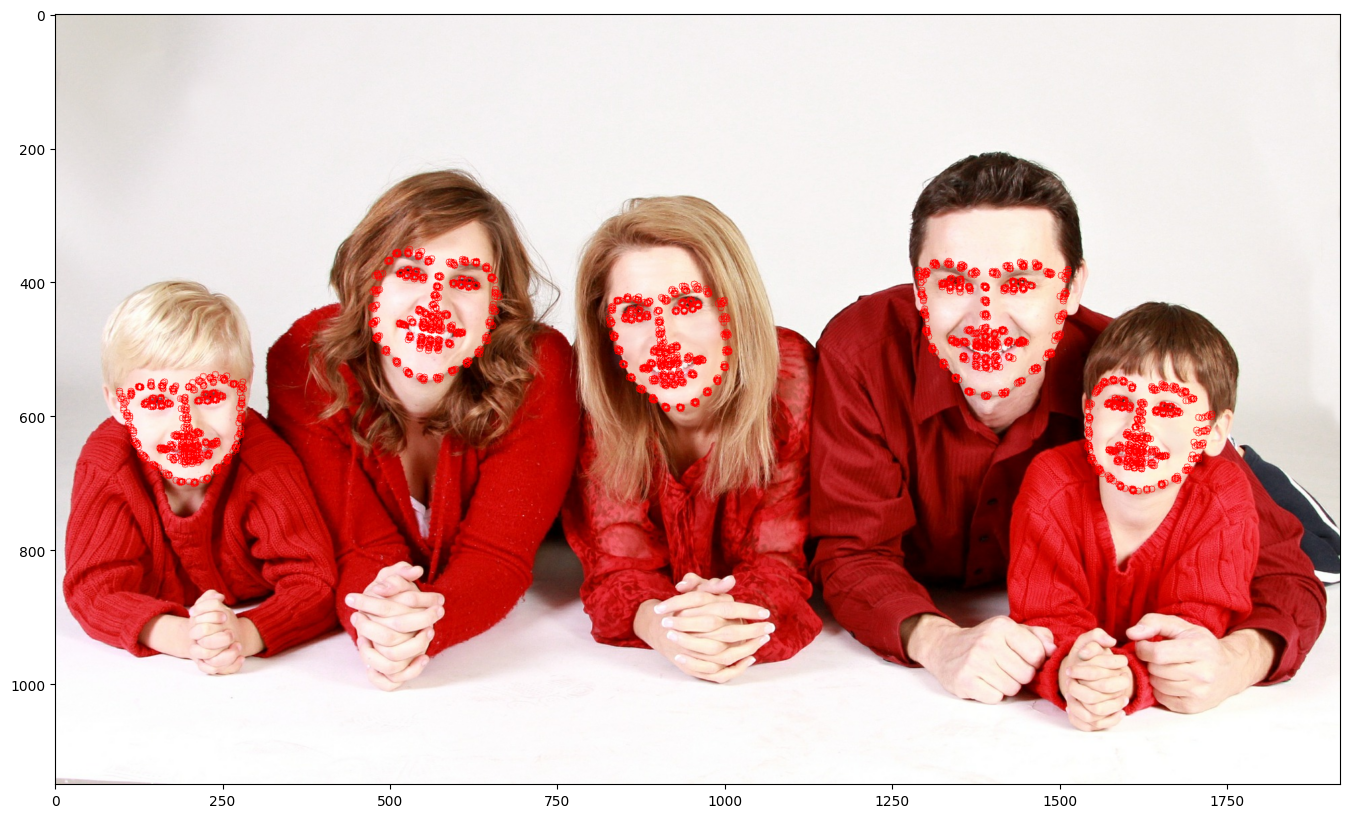

In [24]:
# Landmarken werden gespeichert in results/family_i.txt
landmarksBasename = "results/family"

# Liste aller Landmarken
landmarksAll = []

# Iteriere über alle erkannten Rechtecke mit Gesichtern
for i in range(0, len(faceRects)):
  newRect = dlib.rectangle(int(faceRects[i].left()),
                          int(faceRects[i].top()),
                          int(faceRects[i].right()),
                          int(faceRects[i].bottom()))

  # Benutze Landmarken-Erkennung
  landmarks = landmarkDetector(img, newRect)

  # Gib Anzahl der Landmarken im ersten Gesicht aus
  if i==0:
    print("Anzahl Landmarken:", len(landmarks.parts()))
  
  # Landmarken
  landmarksAll.append(landmarks)
  landmark_text = ""
  # Landmarken rendern
  for p in landmarks.parts():
      img = cv2.circle(img,(p.x,p.y),5,255)
      landmark_text = landmark_text + "\n" +  str(p.x) + " " + str(p.y)
    

  # Landmarken abspeichern
  landmarksFileName = landmarksBasename +"_"+ str(i)+ ".txt"
  print("Speichere Landmarken in", landmarksFileName)
  with open(landmarksFileName, "w") as f:
     f.write(landmark_text)
     
     
  

# Ergebnisdatei anlegen
outputFileName = "results/familyLandmarks.jpg"
print("Speichere Ausgabebild in", outputFileName)

# Bild schreiben
cv2.imwrite(outputFileName, img)

# In RGB konvertieren
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Bild anzeigen
plt.imshow(img)